In [5]:
# ============================================================
# IT3091 Machine Learning - Assignment
# Project: Early Identification of At-Risk Students Using ML
# Group: 2026-AI-53
# Member: Asma M.A.F (IT24103546)
# Main Area: Preprocessing & Feature Engineering
# Model: Random Forest
# Track: Guided Data Track | Domain: Education
# Datasets: Student Performance (Math + Portuguese) - UCI ID 320
# ============================================================

# --- Standard imports ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# --- Reproducibility ---
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# --- Sklearn: model selection ---
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, cross_val_predict,
    RandomizedSearchCV
)

# --- Sklearn: preprocessing ---
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# --- Sklearn: models ---
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier

# --- Sklearn: metrics ---
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve, auc
)

# --- Display settings ---
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Setup complete.")
print("Random seed:", RANDOM_SEED)

Setup complete.
Random seed: 42


In [6]:
# ============================================================
# Download and load both datasets
# ============================================================
!wget -q https://archive.ics.uci.edu/static/public/320/student+performance.zip -O student.zip
!mkdir -p student_data
!unzip -o student.zip -d student_data/ > /dev/null 2>&1
!unzip -o student_data/student.zip -d student_data/ > /dev/null 2>&1
!rm -f student_data/student.zip student_data/.student.zip_old

# Verify
import os
print("Files in student_data/:", os.listdir('student_data/'))

'wget' is not recognized as an internal or external command,
operable program or batch file.
A subdirectory or file -p already exists.
Error occurred while processing: -p.
A subdirectory or file student_data already exists.
Error occurred while processing: student_data.
The system cannot find the path specified.
The system cannot find the path specified.


Files in student_data/: []


'rm' is not recognized as an internal or external command,
operable program or batch file.


In [7]:

from pathlib import Path
import pandas as pd

# Locate the project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Load datasets from the existing raw-data folder
DATA_DIR = PROJECT_ROOT / "data" / "raw"

math_path = DATA_DIR / "student-mat.csv"
port_path = DATA_DIR / "student-por.csv"

print("Dataset folder:", DATA_DIR)
print("Math file exists:", math_path.exists())
print("Portuguese file exists:", port_path.exists())

if not math_path.exists() or not port_path.exists():
    raise FileNotFoundError(f"Dataset files not found in {DATA_DIR}")

df_math = pd.read_csv(math_path, sep=";")
df_por = pd.read_csv(port_path, sep=";")

print("\nMath dataset shape:", df_math.shape)
print("Portuguese dataset shape:", df_por.shape)
print("Columns identical:", list(df_math.columns) == list(df_por.columns))


Dataset folder: c:\Users\USER\student-risk-intelligence\data\raw
Math file exists: True
Portuguese file exists: True

Math dataset shape: (395, 33)
Portuguese dataset shape: (649, 33)
Columns identical: True


In [8]:
# ============================================================
# Data Understanding — Target Construction
# ============================================================
def add_target(df):
    df = df.copy()
    df['at_risk'] = (df['G3'] < 10).astype(int)
    return df

df_math = add_target(df_math)
df_por  = add_target(df_por)

# Class balance check
for name, df in [("Math", df_math), ("Portuguese", df_por)]:
    counts = df['at_risk'].value_counts().sort_index()
    pcts   = df['at_risk'].value_counts(normalize=True).sort_index() * 100
    print(f"\n{name} — Class Balance:")
    print(pd.DataFrame({'Count': counts.values, 'Percentage': pcts.round(2).values},
                       index=['Not-At-Risk', 'At-Risk']))


Math — Class Balance:
             Count  Percentage
Not-At-Risk    265       67.09
At-Risk        130       32.91

Portuguese — Class Balance:
             Count  Percentage
Not-At-Risk    549       84.59
At-Risk        100       15.41


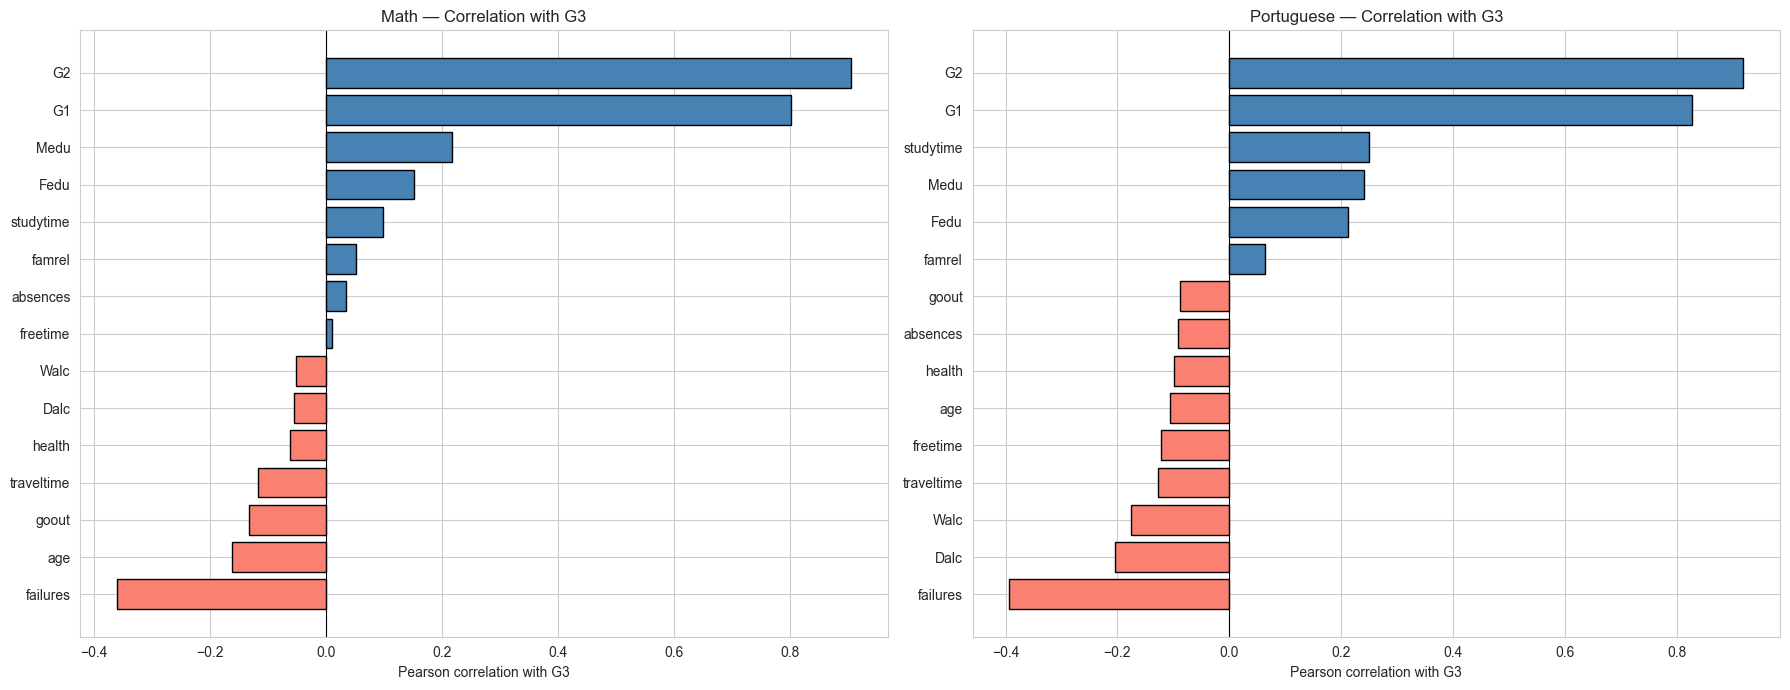


Math — Top 5 correlations with G3:
G2           0.905
G1           0.801
Medu         0.217
Fedu         0.152
studytime    0.098
Name: G3, dtype: float64

Portuguese — Top 5 correlations with G3:
G2           0.919
G1           0.826
studytime    0.250
Medu         0.240
Fedu         0.212
Name: G3, dtype: float64


In [9]:
# ============================================================
# EDA — Correlation with G3 (both datasets)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (name, df) in zip(axes, [("Math", df_math), ("Portuguese", df_por)]):
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    corr_g3 = df[numeric_cols].corr()['G3'].drop(['G3', 'at_risk']).sort_values()
    colors = ['salmon' if v < 0 else 'steelblue' for v in corr_g3.values]
    ax.barh(corr_g3.index, corr_g3.values, color=colors, edgecolor='black')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{name} — Correlation with G3')
    ax.set_xlabel('Pearson correlation with G3')

plt.tight_layout()
plt.show()

# Top 5 features
for name, df in [("Math", df_math), ("Portuguese", df_por)]:
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    top = df[numeric_cols].corr()['G3'].drop(['G3', 'at_risk']).sort_values(ascending=False)
    print(f"\n{name} — Top 5 correlations with G3:")
    print(top.head(5).round(3))

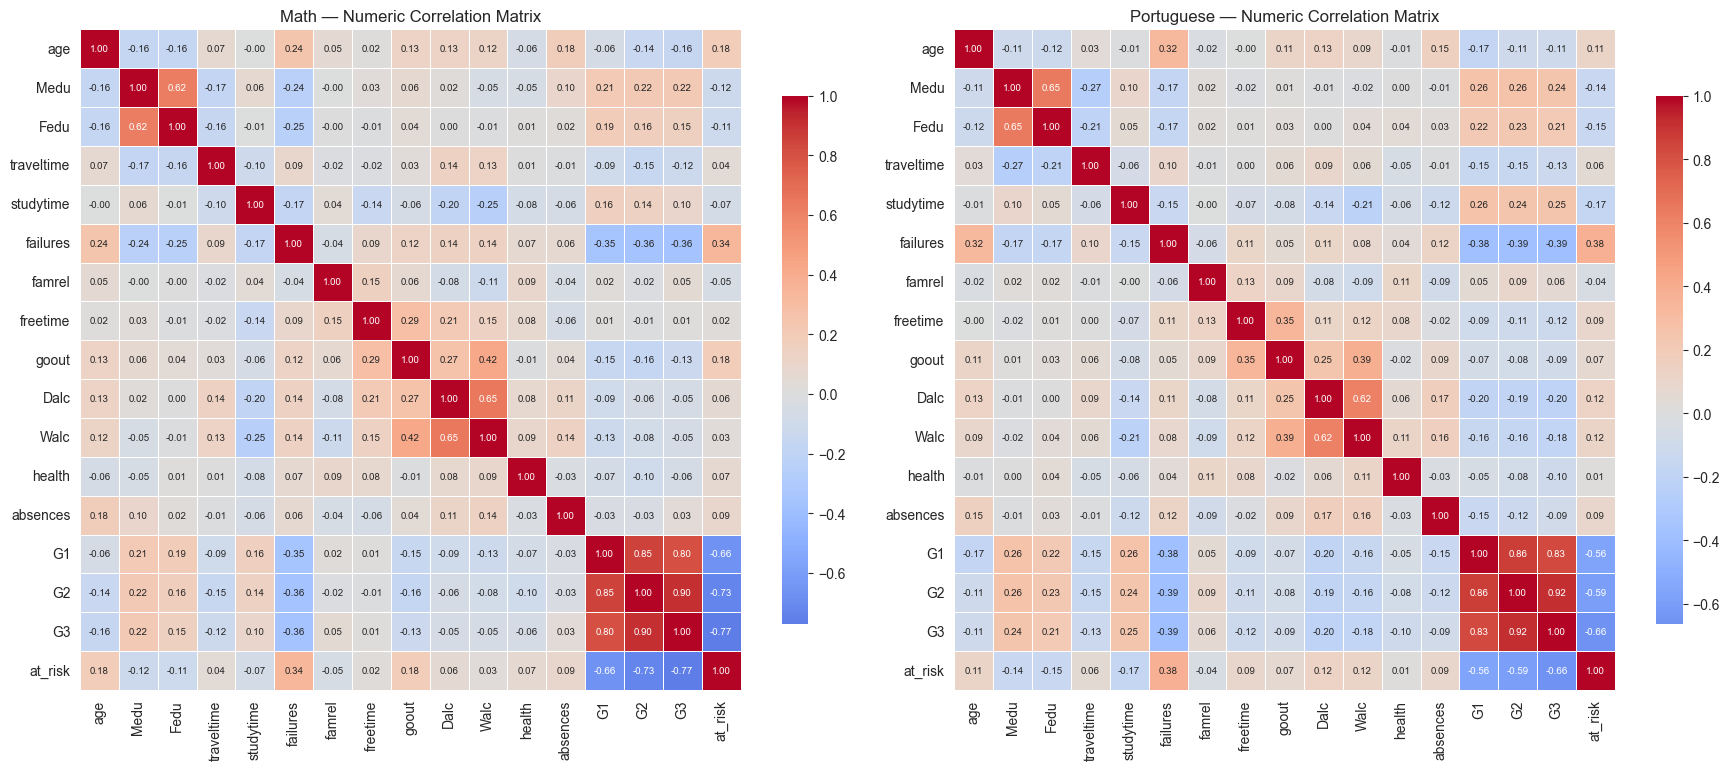

In [10]:
# ============================================================
# EDA — Correlation Heatmap (numeric features)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, (name, df) in zip(axes, [("Math", df_math), ("Portuguese", df_por)]):
    numeric_df = df.select_dtypes(include=[np.number])
    corr = numeric_df.corr()
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                square=True, linewidths=0.5, cbar_kws={'shrink': 0.7},
                annot_kws={'size': 7}, ax=ax)
    ax.set_title(f'{name} — Numeric Correlation Matrix')

plt.tight_layout()
plt.show()

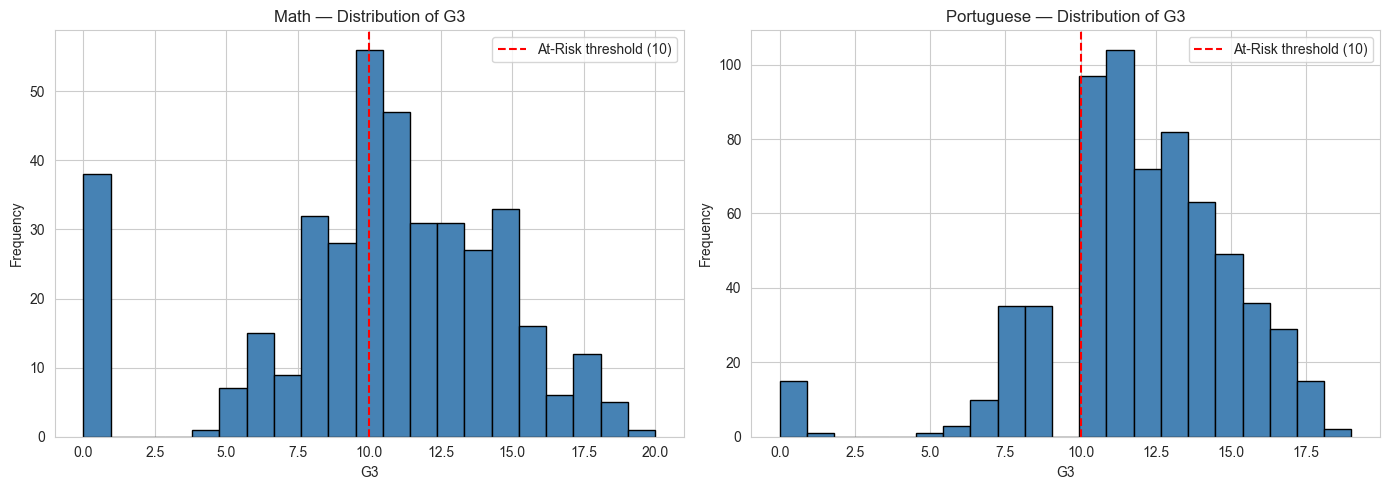

In [11]:
# ============================================================
# EDA — G3 Distribution (both datasets)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, df) in zip(axes, [("Math", df_math), ("Portuguese", df_por)]):
    ax.hist(df['G3'], bins=21, edgecolor='black', color='steelblue')
    ax.axvline(10, color='red', linestyle='--', label='At-Risk threshold (10)')
    ax.set_title(f'{name} — Distribution of G3')
    ax.set_xlabel('G3')
    ax.set_ylabel('Frequency')
    ax.legend()

plt.tight_layout()
plt.show()

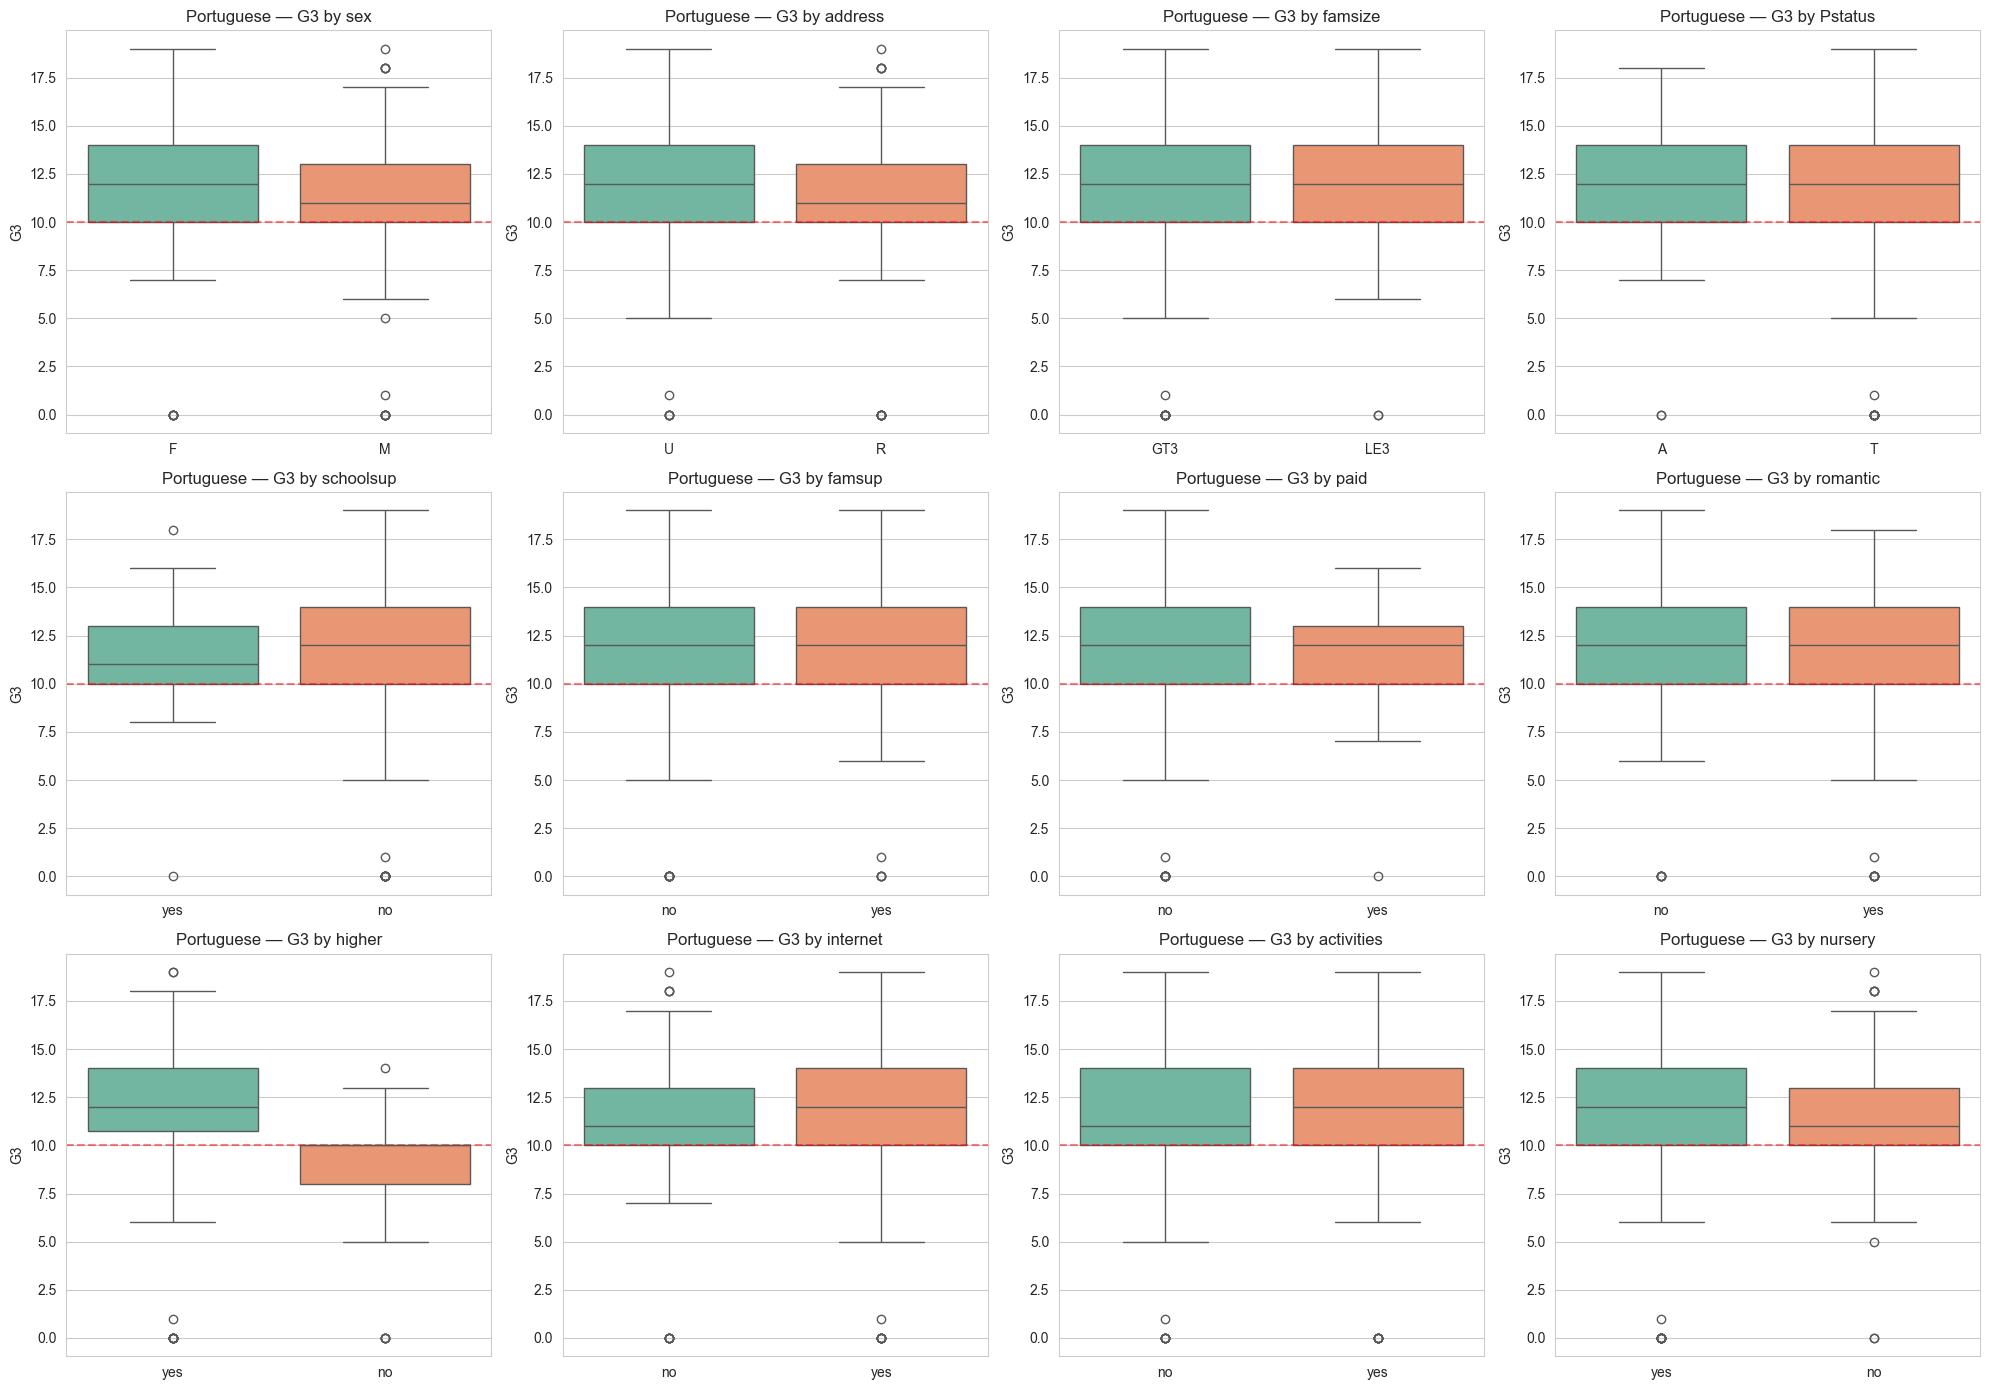

In [12]:
# ============================================================
# EDA — G3 vs categorical features (Portuguese)
# ============================================================
cat_features = ['sex', 'address', 'famsize', 'Pstatus',
                'schoolsup', 'famsup', 'paid', 'romantic',
                'higher', 'internet', 'activities', 'nursery']

fig, axes = plt.subplots(3, 4, figsize=(20, 14))
for ax, col in zip(axes.flatten(), cat_features):
    sns.boxplot(data=df_por, x=col, y='G3', ax=ax, palette='Set2')
    ax.axhline(10, color='red', linestyle='--', alpha=0.5)
    ax.set_title(f'Portuguese — G3 by {col}')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

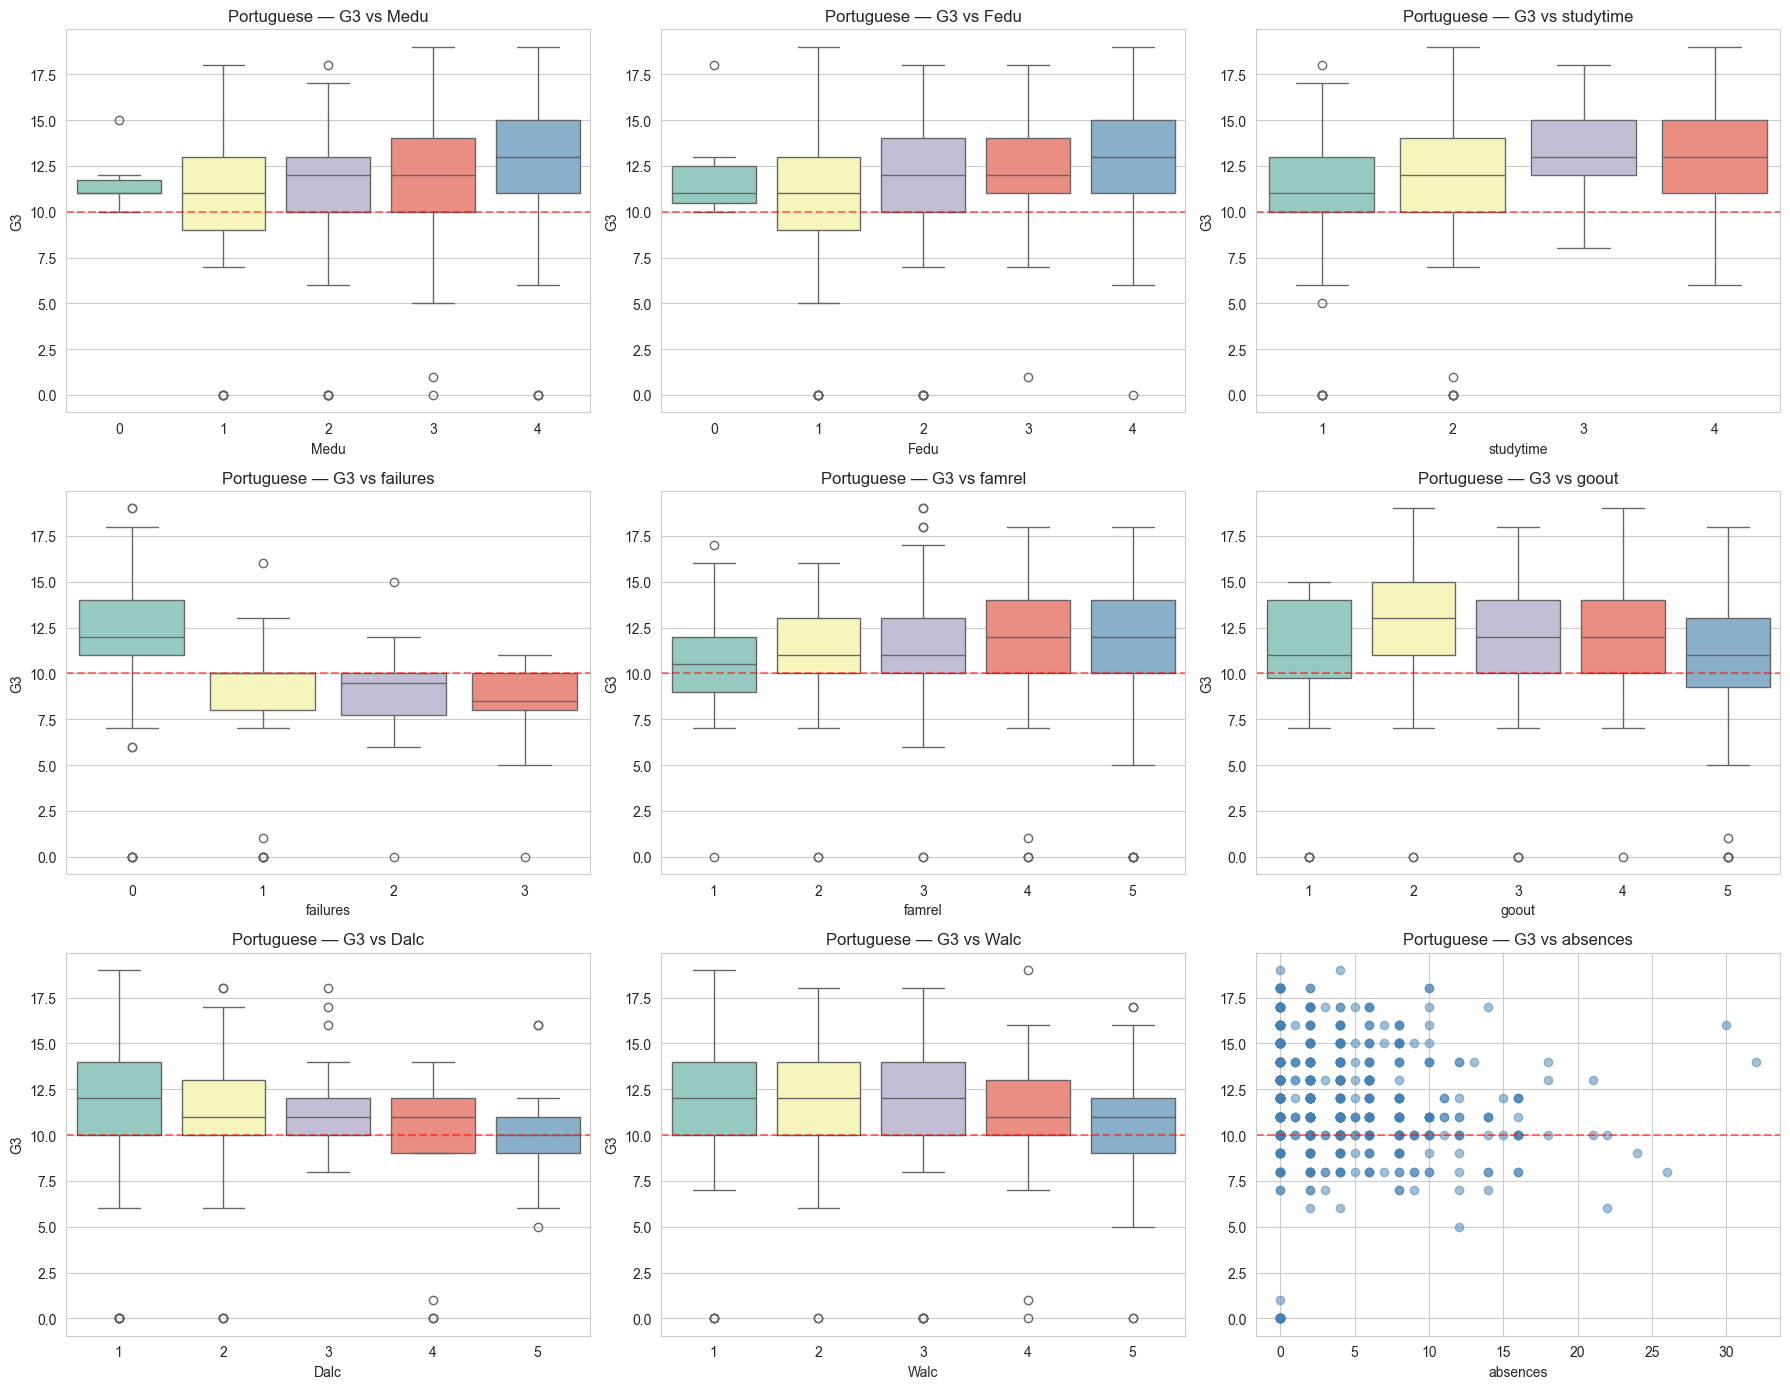

In [13]:
# ============================================================
# EDA — G3 vs ordinal/numeric features (Portuguese)
# ============================================================
ordinal_num = ['Medu', 'Fedu', 'studytime', 'failures',
               'famrel', 'goout', 'Dalc', 'Walc', 'absences']

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, col in zip(axes.flatten(), ordinal_num):
    if df_por[col].nunique() <= 6:
        sns.boxplot(data=df_por, x=col, y='G3', ax=ax, palette='Set3')
        ax.axhline(10, color='red', linestyle='--', alpha=0.5)
    else:
        ax.scatter(df_por[col], df_por['G3'], alpha=0.5, color='steelblue')
        ax.axhline(10, color='red', linestyle='--', alpha=0.5)
    ax.set_title(f'Portuguese — G3 vs {col}')
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

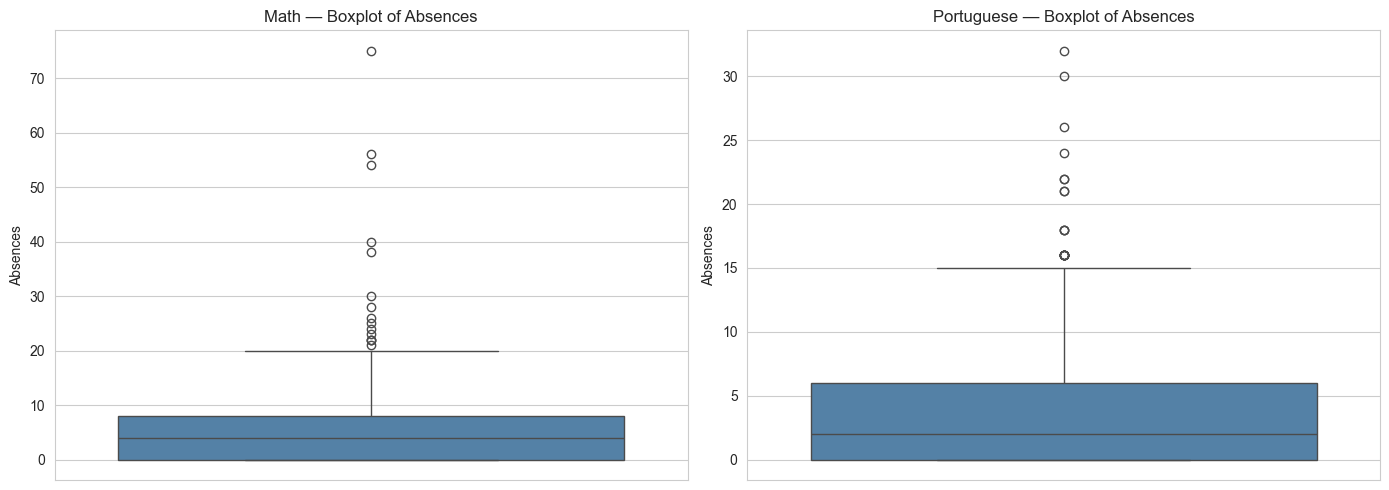

Absences quantiles — Portuguese:
0.50     2.0
0.75     6.0
0.90    10.0
0.95    12.0
0.99    21.0
1.00    32.0
Name: absences, dtype: float64

Students with absences > 20: 8 (1.2%)


In [14]:
# ============================================================
# EDA — Absences Outliers
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, df) in zip(axes, [("Math", df_math), ("Portuguese", df_por)]):
    sns.boxplot(y=df['absences'], ax=ax, color='steelblue')
    ax.set_title(f'{name} — Boxplot of Absences')
    ax.set_ylabel('Absences')
plt.tight_layout()
plt.show()

print("Absences quantiles — Portuguese:")
print(df_por['absences'].quantile([0.5, 0.75, 0.9, 0.95, 0.99, 1.0]).round(1))
print(f"\nStudents with absences > 20: {(df_por['absences'] > 20).sum()} "
      f"({(df_por['absences'] > 20).mean()*100:.1f}%)")

In [15]:
# ============================================================
# Preprocessing Pipeline
# ============================================================

# Column type identification
binary_cols = [
    'school', 'sex', 'address', 'famsize', 'Pstatus',
    'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
    'higher', 'internet', 'romantic'
]
nominal_cols = ['Mjob', 'Fjob', 'reason', 'guardian']
ordinal_cols = [
    'Medu', 'Fedu', 'traveltime', 'studytime',
    'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health'
]
numeric_cols = ['age', 'absences', 'failures']
grade_cols   = ['G1', 'G2']

# --- Preprocessing sub-pipelines ---
nominal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
ordinal_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
])
binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder())
])
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# --- Feature Set A preprocessor (no G1/G2) ---
preprocessor_A = ColumnTransformer([
    ('nom', nominal_transformer, nominal_cols),
    ('ord', ordinal_transformer, ordinal_cols),
    ('bin', binary_pipeline, binary_cols),
    ('num', numeric_transformer, numeric_cols),
], remainder='drop')

# --- Feature Set B preprocessor (with G1/G2) ---
numeric_cols_B = numeric_cols + grade_cols
numeric_transformer_B = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocessor_B = ColumnTransformer([
    ('nom', nominal_transformer, nominal_cols),
    ('ord', ordinal_transformer, ordinal_cols),
    ('bin', binary_pipeline, binary_cols),
    ('num', numeric_transformer_B, numeric_cols_B),
], remainder='drop')

# --- Prepare X, y ---
def prepare_Xy(df):
    return df.drop(columns=['G3', 'at_risk']), df['at_risk']

X_por, y_por   = prepare_Xy(df_por)
X_math, y_math = prepare_Xy(df_math)

print(f"Portuguese X shape: {X_por.shape}")
print(f"Math X shape:       {X_math.shape}")
print(f"Feature Set A: 30 features (no G1/G2)")
print(f"Feature Set B: 32 features (with G1/G2)")

Portuguese X shape: (649, 32)
Math X shape:       (395, 32)
Feature Set A: 30 features (no G1/G2)
Feature Set B: 32 features (with G1/G2)


In [16]:
# ============================================================
# Train/Test Split + Stratified 5-fold CV
# ============================================================
TEST_SIZE = 0.20

# Portuguese
X_por_train, X_por_test, y_por_train, y_por_test = train_test_split(
    X_por, y_por, test_size=TEST_SIZE, stratify=y_por, random_state=RANDOM_SEED
)

# Math
X_math_train, X_math_test, y_math_train, y_math_test = train_test_split(
    X_math, y_math, test_size=TEST_SIZE, stratify=y_math, random_state=RANDOM_SEED
)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Threshold range and precision floor (group conventions)
THRESHOLD_RANGE = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
MIN_PRECISION = 0.30

print("Train/test split summary:")
print(f"  Portuguese: train={len(X_por_train)}, test={len(X_por_test)}")
print(f"  Math:       train={len(X_math_train)}, test={len(X_math_test)}")

Train/test split summary:
  Portuguese: train=519, test=130
  Math:       train=316, test=79


In [17]:
# ============================================================
# Baseline — Majority Class Classifier
# ============================================================
baseline_pipe = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED))
])
baseline_pipe.fit(X_por_train, y_por_train)
y_pred_baseline = baseline_pipe.predict(X_por_test)
y_proba_baseline = baseline_pipe.predict_proba(X_por_test)[:, 1]

baseline_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_pred_baseline),
    'precision': precision_score(y_por_test, y_pred_baseline, zero_division=0),
    'recall':    recall_score(y_por_test, y_pred_baseline, zero_division=0),
    'f1':        f1_score(y_por_test, y_pred_baseline, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_proba_baseline),
    'pr_auc':    average_precision_score(y_por_test, y_proba_baseline),
}

print("Baseline — Portuguese, Set A:")
for m, v in baseline_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Baseline — Portuguese, Set A:
  accuracy  : 0.8462
  precision : 0.0000
  recall    : 0.0000
  f1        : 0.0000
  roc_auc   : 0.5000
  pr_auc    : 0.1538


In [18]:
# ============================================================
# Default Random Forest (Reference Point)
# ============================================================
rf_default = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_SEED,
    class_weight='balanced',
    n_jobs=-1
)

pipe_rf_default = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', rf_default)
])

# CV scores
cv_pr_auc = cross_val_score(pipe_rf_default, X_por_train, y_por_train,
                             cv=cv_strategy, scoring='average_precision')
cv_roc_auc = cross_val_score(pipe_rf_default, X_por_train, y_por_train,
                              cv=cv_strategy, scoring='roc_auc')

print(f"Default RF — Portuguese, Set A:")
print(f"  CV PR-AUC:  {cv_pr_auc.mean():.4f} (± {cv_pr_auc.std():.4f})")
print(f"  CV ROC-AUC: {cv_roc_auc.mean():.4f} (± {cv_roc_auc.std():.4f})")

# Fit and test
pipe_rf_default.fit(X_por_train, y_por_train)
y_pred_rf_default = pipe_rf_default.predict(X_por_test)
y_proba_rf_default = pipe_rf_default.predict_proba(X_por_test)[:, 1]

rf_default_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_pred_rf_default),
    'precision': precision_score(y_por_test, y_pred_rf_default, zero_division=0),
    'recall':    recall_score(y_por_test, y_pred_rf_default, zero_division=0),
    'f1':        f1_score(y_por_test, y_pred_rf_default, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_proba_rf_default),
    'pr_auc':    average_precision_score(y_por_test, y_proba_rf_default),
}
print(f"\nTest metrics (threshold=0.5):")
for m, v in rf_default_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Default RF — Portuguese, Set A:
  CV PR-AUC:  0.5015 (± 0.1266)
  CV ROC-AUC: 0.8275 (± 0.0647)

Test metrics (threshold=0.5):
  accuracy  : 0.8231
  precision : 0.0000
  recall    : 0.0000
  f1        : 0.0000
  roc_auc   : 0.8298
  pr_auc    : 0.3768


In [19]:
# ============================================================
# Random Forest — Hyperparameter Tuning
# ============================================================

param_dist = {
    'classifier__n_estimators':      [100, 200, 300, 500],
    'classifier__max_depth':         [None, 5, 10, 15, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf':  [1, 2, 4],
    'classifier__max_features':      ['sqrt', 'log2', 0.5],
    'classifier__class_weight':      ['balanced', 'balanced_subsample'],
}

pipe_for_tuning = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1))
])

search = RandomizedSearchCV(
    estimator=pipe_for_tuning,
    param_distributions=param_dist,
    n_iter=60,
    scoring='average_precision',
    cv=cv_strategy,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

print("Starting RandomizedSearchCV (2–4 min)...")
search.fit(X_por_train, y_por_train)

best_params = {k.replace('classifier__', ''): v for k, v in search.best_params_.items()}

print("\nBest Hyperparameters:")
for k, v in best_params.items():
    print(f"  {k}: {v}")
print(f"\nBest CV PR-AUC: {search.best_score_:.4f}")

Starting RandomizedSearchCV (2–4 min)...
Fitting 5 folds for each of 60 candidates, totalling 300 fits


TerminatedWorkerError: A worker process managed by the executor was unexpectedly terminated. This could be caused by a segmentation fault while calling the function or by an excessive memory usage causing the Operating System to kill the worker.

Detailed tracebacks of the workers should have been printed to stderr in the executor process if faulthandler was not disabled.

In [ ]:
# ============================================================
# Threshold Optimization — Random Forest
# ============================================================

tuned_pipe = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1, **best_params))
])

# Out-of-fold probabilities
y_train_proba = cross_val_predict(
    tuned_pipe, X_por_train, y_por_train,
    cv=cv_strategy, method='predict_proba', n_jobs=-1
)[:, 1]

# Sweep thresholds
threshold_results = []
for t in THRESHOLD_RANGE:
    y_pred_t = (y_train_proba >= t).astype(int)
    threshold_results.append({
        'threshold': t,
        'precision': precision_score(y_por_train, y_pred_t, zero_division=0),
        'recall':    recall_score(y_por_train, y_pred_t, zero_division=0),
        'f1':        f1_score(y_por_train, y_pred_t, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_results)
print("Threshold sweep (out-of-fold, Portuguese, Set A):")
print(threshold_df.round(4).to_string(index=False))

# Select optimal
valid = threshold_df[threshold_df['precision'] >= MIN_PRECISION]
if len(valid) > 0:
    optimal_row = valid.loc[valid['f1'].idxmax()]
else:
    optimal_row = threshold_df.loc[threshold_df['f1'].idxmax()]

OPTIMAL_THRESHOLD = float(optimal_row['threshold'])
print(f"\nOptimal threshold: {OPTIMAL_THRESHOLD}")
print(f"  Precision: {optimal_row['precision']:.4f}")
print(f"  Recall:    {optimal_row['recall']:.4f}")
print(f"  F1:        {optimal_row['f1']:.4f}")

Threshold sweep (out-of-fold, Portuguese, Set A):
 threshold  precision  recall     f1
      0.15     0.2299  0.9625 0.3711
      0.20     0.2607  0.9125 0.4056
      0.25     0.3060  0.8875 0.4551
      0.30     0.3722  0.8375 0.5154
      0.35     0.3800  0.7125 0.4957
      0.40     0.4228  0.6500 0.5123
      0.50     0.5224  0.4375 0.4762

Optimal threshold: 0.3
  Precision: 0.3722
  Recall:    0.8375
  F1:        0.5154


In [ ]:
# ============================================================
# Final Test Evaluation — Tuned Random Forest (Portuguese, Set A)
# ============================================================

tuned_pipe.fit(X_por_train, y_por_train)
y_test_proba = tuned_pipe.predict_proba(X_por_test)[:, 1]
y_test_pred  = (y_test_proba >= OPTIMAL_THRESHOLD).astype(int)

rf_A_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_test_pred),
    'precision': precision_score(y_por_test, y_test_pred, zero_division=0),
    'recall':    recall_score(y_por_test, y_test_pred, zero_division=0),
    'f1':        f1_score(y_por_test, y_test_pred, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_test_proba),
    'pr_auc':    average_precision_score(y_por_test, y_test_proba),
}

print("=" * 65)
print(f"TUNED RANDOM FOREST — Portuguese, Set A (threshold={OPTIMAL_THRESHOLD})")
print("=" * 65)
for m, v in rf_A_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

cm = confusion_matrix(y_por_test, y_test_pred)
print(f"\nConfusion matrix:")
print(f"  TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}")

TUNED RANDOM FOREST — Portuguese, Set A (threshold=0.3)
  accuracy  : 0.7385
  precision : 0.3478
  recall    : 0.8000
  f1        : 0.4848
  roc_auc   : 0.8073
  pr_auc    : 0.4070

Confusion matrix:
  TN=80, FP=30, FN=4, TP=16


In [ ]:
# ============================================================
# Random Forest — Feature Set B (with G1/G2)
# ============================================================

pipe_B = Pipeline([
    ('preprocessor', preprocessor_B),
    ('classifier', RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1))
])

search_B = RandomizedSearchCV(
    estimator=pipe_B, param_distributions=param_dist,
    n_iter=60, scoring='average_precision',
    cv=cv_strategy, random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search_B.fit(X_por_train, y_por_train)
best_params_B = {k.replace('classifier__', ''): v for k, v in search_B.best_params_.items()}

print(f"Best CV PR-AUC (Set B): {search_B.best_score_:.4f}")

# Threshold optimization for Set B
tuned_pipe_B = Pipeline([
    ('preprocessor', preprocessor_B),
    ('classifier', RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1, **best_params_B))
])
y_train_proba_B = cross_val_predict(tuned_pipe_B, X_por_train, y_por_train,
                                     cv=cv_strategy, method='predict_proba', n_jobs=-1)[:, 1]

threshold_B = []
for t in THRESHOLD_RANGE:
    yt = (y_train_proba_B >= t).astype(int)
    threshold_B.append({
        'threshold': t,
        'precision': precision_score(y_por_train, yt, zero_division=0),
        'recall':    recall_score(y_por_train, yt, zero_division=0),
        'f1':        f1_score(y_por_train, yt, zero_division=0),
    })
threshold_df_B = pd.DataFrame(threshold_B)
valid_B = threshold_df_B[threshold_df_B['precision'] >= MIN_PRECISION]
opt_B = valid_B.loc[valid_B['f1'].idxmax()] if len(valid_B) > 0 else threshold_df_B.loc[threshold_df_B['f1'].idxmax()]
OPTIMAL_THRESHOLD_B = float(opt_B['threshold'])

# Final test
tuned_pipe_B.fit(X_por_train, y_por_train)
y_test_proba_B = tuned_pipe_B.predict_proba(X_por_test)[:, 1]
y_test_pred_B  = (y_test_proba_B >= OPTIMAL_THRESHOLD_B).astype(int)

rf_B_metrics = {
    'accuracy':  accuracy_score(y_por_test, y_test_pred_B),
    'precision': precision_score(y_por_test, y_test_pred_B, zero_division=0),
    'recall':    recall_score(y_por_test, y_test_pred_B, zero_division=0),
    'f1':        f1_score(y_por_test, y_test_pred_B, zero_division=0),
    'roc_auc':   roc_auc_score(y_por_test, y_test_proba_B),
    'pr_auc':    average_precision_score(y_por_test, y_test_proba_B),
}

print(f"\nSet B (threshold={OPTIMAL_THRESHOLD_B}):")
for m, v in rf_B_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best CV PR-AUC (Set B): 0.8859

Set B (threshold=0.4):
  accuracy  : 0.8846
  precision : 0.5862
  recall    : 0.8500
  f1        : 0.6939
  roc_auc   : 0.9475
  pr_auc    : 0.8523


In [ ]:
# ============================================================
# Random Forest — Math Dataset (Set A)
# ============================================================

pipe_math = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1))
])
search_math = RandomizedSearchCV(
    estimator=pipe_math, param_distributions=param_dist,
    n_iter=60, scoring='average_precision',
    cv=cv_strategy, random_state=RANDOM_SEED, n_jobs=-1, verbose=1
)
search_math.fit(X_math_train, y_math_train)
best_params_math = {k.replace('classifier__', ''): v for k, v in search_math.best_params_.items()}

print(f"Best CV PR-AUC (Math, Set A): {search_math.best_score_:.4f}")

# Threshold optimization
tuned_pipe_math = Pipeline([
    ('preprocessor', preprocessor_A),
    ('classifier', RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1, **best_params_math))
])
y_math_proba = cross_val_predict(tuned_pipe_math, X_math_train, y_math_train,
                                  cv=cv_strategy, method='predict_proba', n_jobs=-1)[:, 1]

thr_math = []
for t in THRESHOLD_RANGE:
    yt = (y_math_proba >= t).astype(int)
    thr_math.append({
        'threshold': t,
        'precision': precision_score(y_math_train, yt, zero_division=0),
        'recall':    recall_score(y_math_train, yt, zero_division=0),
        'f1':        f1_score(y_math_train, yt, zero_division=0),
    })
thr_df_math = pd.DataFrame(thr_math)
valid_m = thr_df_math[thr_df_math['precision'] >= MIN_PRECISION]
opt_m = valid_m.loc[valid_m['f1'].idxmax()] if len(valid_m) > 0 else thr_df_math.loc[thr_df_math['f1'].idxmax()]
OPTIMAL_THRESHOLD_MATH = float(opt_m['threshold'])

# Final test
tuned_pipe_math.fit(X_math_train, y_math_train)
y_math_test_proba = tuned_pipe_math.predict_proba(X_math_test)[:, 1]
y_math_test_pred  = (y_math_test_proba >= OPTIMAL_THRESHOLD_MATH).astype(int)

rf_math_metrics = {
    'accuracy':  accuracy_score(y_math_test, y_math_test_pred),
    'precision': precision_score(y_math_test, y_math_test_pred, zero_division=0),
    'recall':    recall_score(y_math_test, y_math_test_pred, zero_division=0),
    'f1':        f1_score(y_math_test, y_math_test_pred, zero_division=0),
    'roc_auc':   roc_auc_score(y_math_test, y_math_test_proba),
    'pr_auc':    average_precision_score(y_math_test, y_math_test_proba),
}

print(f"\nMath Set A (threshold={OPTIMAL_THRESHOLD_MATH}):")
for m, v in rf_math_metrics.items():
    print(f"  {m:<10}: {v:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Best CV PR-AUC (Math, Set A): 0.5697

Math Set A (threshold=0.25):
  accuracy  : 0.4557
  precision : 0.3692
  recall    : 0.9231
  f1        : 0.5275
  roc_auc   : 0.7329
  pr_auc    : 0.5811


Top 15 Feature Importances — Random Forest (Set A):
      feature  importance
     failures      0.1409
       school      0.1193
       higher      0.0528
    studytime      0.0482
         Fedu      0.0474
     absences      0.0474
         Walc      0.0392
        goout      0.0390
       famrel      0.0380
     freetime      0.0339
         Medu      0.0331
       health      0.0294
          age      0.0270
reason_course      0.0197
         Dalc      0.0197


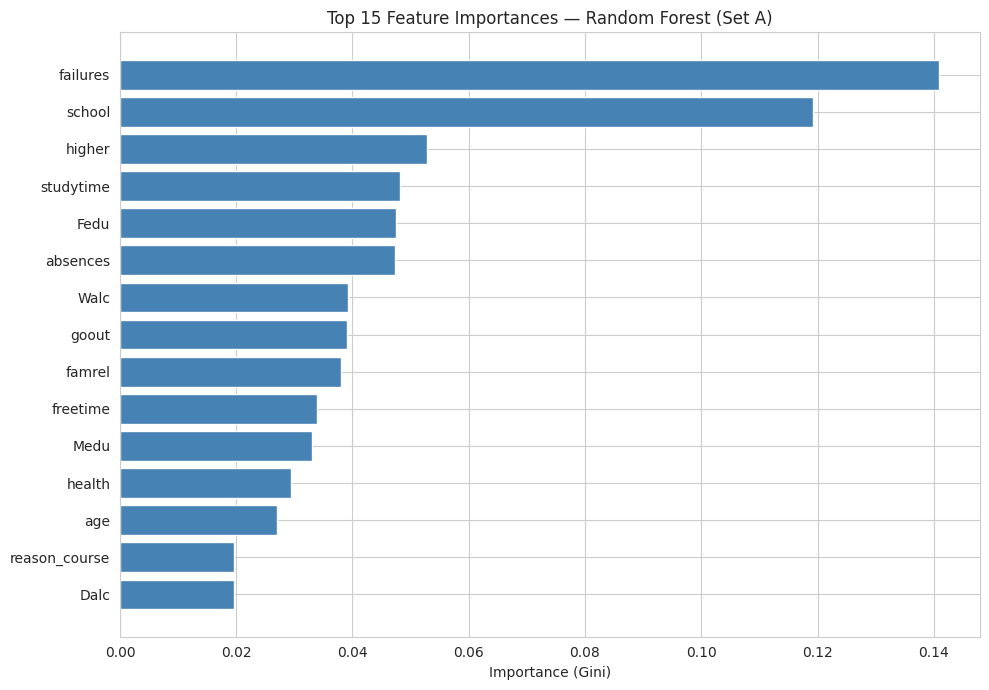

In [ ]:
# ============================================================
# Feature Importances — Random Forest
# ============================================================

# Get feature names post-preprocessing
feature_names = []
feature_names += list(
    tuned_pipe.named_steps['preprocessor']
    .named_transformers_['nom'].named_steps['onehot']
    .get_feature_names_out(nominal_cols)
)
feature_names += ordinal_cols
feature_names += binary_cols
feature_names += numeric_cols

importances = tuned_pipe.named_steps['classifier'].feature_importances_

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).reset_index(drop=True)

print("Top 15 Feature Importances — Random Forest (Set A):")
print(importance_df.head(15).round(4).to_string(index=False))

# Visualization
fig, ax = plt.subplots(figsize=(10, 7))
top_15 = importance_df.head(15)
ax.barh(top_15['feature'][::-1], top_15['importance'][::-1], color='steelblue')
ax.set_xlabel('Importance (Gini)')
ax.set_title('Top 15 Feature Importances — Random Forest (Set A)')
plt.tight_layout()
plt.show()

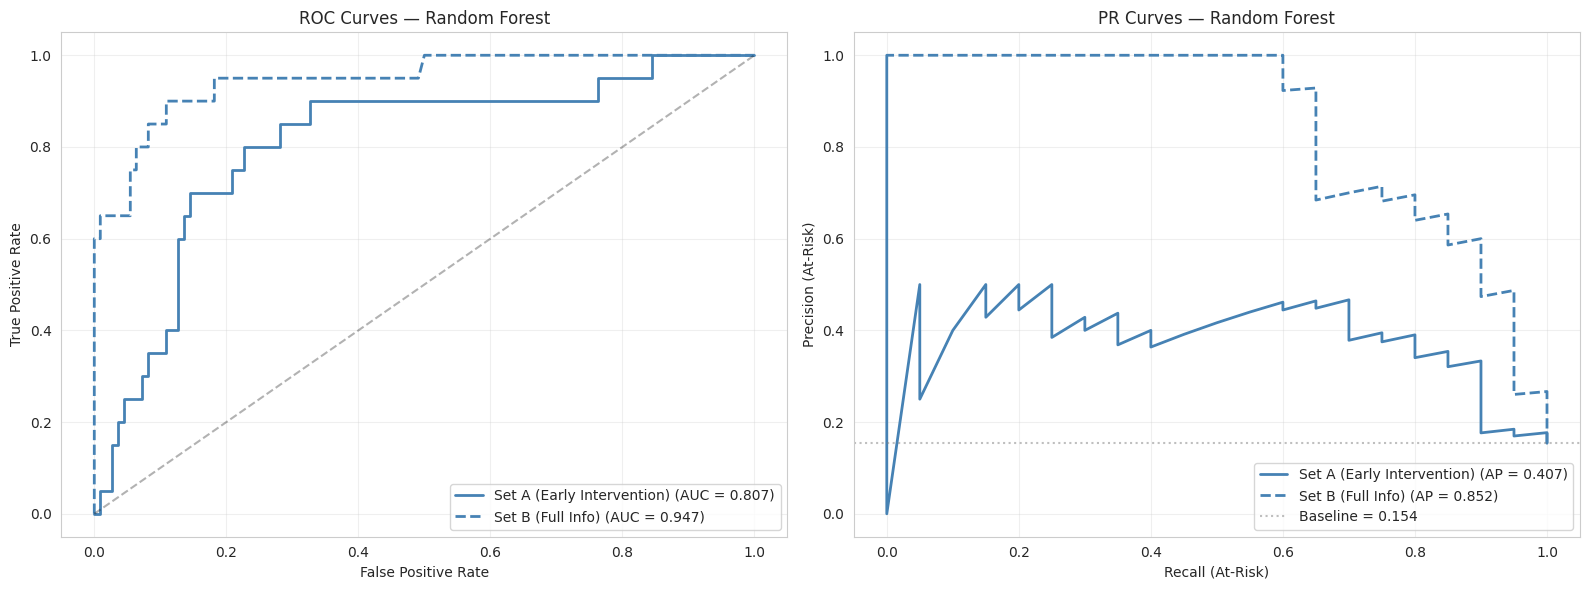

In [ ]:
# ============================================================
# ROC and PR Curves — Set A vs Set B
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC
ax = axes[0]
for label, y_true, y_proba, ls in [
    ('Set A (Early Intervention)', y_por_test, y_test_proba, '-'),
    ('Set B (Full Info)', y_por_test, y_test_proba_B, '--'),
]:
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    ax.plot(fpr, tpr, color='steelblue', linestyle=ls, linewidth=2,
            label=f'{label} (AUC = {auc(fpr, tpr):.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Random Forest')
ax.legend()
ax.grid(alpha=0.3)

# PR
ax = axes[1]
for label, y_true, y_proba, ls in [
    ('Set A (Early Intervention)', y_por_test, y_test_proba, '-'),
    ('Set B (Full Info)', y_por_test, y_test_proba_B, '--'),
]:
    prec, rec, _ = precision_recall_curve(y_true, y_proba)
    ap = average_precision_score(y_true, y_proba)
    ax.plot(rec, prec, color='steelblue', linestyle=ls, linewidth=2,
            label=f'{label} (AP = {ap:.3f})')
ax.axhline(y_por_test.mean(), color='gray', linestyle=':', alpha=0.5,
           label=f'Baseline = {y_por_test.mean():.3f}')
ax.set_xlabel('Recall (At-Risk)')
ax.set_ylabel('Precision (At-Risk)')
ax.set_title('PR Curves — Random Forest')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Random Forest — Results Summary
# ============================================================

summary = pd.DataFrame([
    {'Model': 'Baseline', 'Dataset': 'Portuguese', 'Set': 'A', 'Threshold': 0.50, **baseline_metrics},
    {'Model': 'RF (default)', 'Dataset': 'Portuguese', 'Set': 'A', 'Threshold': 0.50, **rf_default_metrics},
    {'Model': 'RF (tuned)', 'Dataset': 'Portuguese', 'Set': 'A', 'Threshold': OPTIMAL_THRESHOLD, **rf_A_metrics},
    {'Model': 'RF (tuned)', 'Dataset': 'Portuguese', 'Set': 'B', 'Threshold': OPTIMAL_THRESHOLD_B, **rf_B_metrics},
    {'Model': 'RF (tuned)', 'Dataset': 'Math', 'Set': 'A', 'Threshold': OPTIMAL_THRESHOLD_MATH, **rf_math_metrics},
])

summary = summary[['Model', 'Dataset', 'Set', 'Threshold',
                   'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']]

print("=" * 100)
print("RANDOM FOREST — RESULTS SUMMARY")
print("=" * 100)
print(summary.round(4).to_string(index=False))

RANDOM FOREST — RESULTS SUMMARY
       Model    Dataset Set  Threshold  accuracy  precision  recall     f1  roc_auc  pr_auc
    Baseline Portuguese   A       0.50    0.8462     0.0000  0.0000 0.0000   0.5000  0.1538
RF (default) Portuguese   A       0.50    0.8231     0.0000  0.0000 0.0000   0.8298  0.3768
  RF (tuned) Portuguese   A       0.30    0.7385     0.3478  0.8000 0.4848   0.8073  0.4070
  RF (tuned) Portuguese   B       0.40    0.8846     0.5862  0.8500 0.6939   0.9475  0.8523
  RF (tuned)       Math   A       0.25    0.4557     0.3692  0.9231 0.5275   0.7329  0.5811


In [ ]:
# ============================================================
# Save Random Forest Results for Group Report
# ============================================================
import json

rf_results = {
    'model': 'Random Forest (tuned)',
    'member': 'Asma M.A.F (IT24103546)',
    'portuguese_set_A': {
        'threshold': OPTIMAL_THRESHOLD,
        'best_params': best_params,
        **{k: round(v, 4) for k, v in rf_A_metrics.items()}
    },
    'portuguese_set_B': {
        'threshold': OPTIMAL_THRESHOLD_B,
        'best_params': best_params_B,
        **{k: round(v, 4) for k, v in rf_B_metrics.items()}
    },
    'math_set_A': {
        'threshold': OPTIMAL_THRESHOLD_MATH,
        'best_params': best_params_math,
        **{k: round(v, 4) for k, v in rf_math_metrics.items()}
    },
    'top_5_features': importance_df.head(5).to_dict(orient='records')
}

print(json.dumps(rf_results, indent=2, default=str))

{
  "model": "Random Forest (tuned)",
  "member": "Asma M.A.F (IT24103546)",
  "portuguese_set_A": {
    "threshold": 0.3,
    "best_params": {
      "n_estimators": 500,
      "min_samples_split": 5,
      "min_samples_leaf": 4,
      "max_features": "sqrt",
      "max_depth": null,
      "class_weight": "balanced"
    },
    "accuracy": 0.7385,
    "precision": 0.3478,
    "recall": 0.8,
    "f1": 0.4848,
    "roc_auc": 0.8073,
    "pr_auc": 0.407
  },
  "portuguese_set_B": {
    "threshold": 0.4,
    "best_params": {
      "n_estimators": 300,
      "min_samples_split": 2,
      "min_samples_leaf": 2,
      "max_features": 0.5,
      "max_depth": null,
      "class_weight": "balanced"
    },
    "accuracy": 0.8846,
    "precision": 0.5862,
    "recall": 0.85,
    "f1": 0.6939,
    "roc_auc": 0.9475,
    "pr_auc": 0.8523
  },
  "math_set_A": {
    "threshold": 0.25,
    "best_params": {
      "n_estimators": 100,
      "min_samples_split": 10,
      "min_samples_leaf": 4,
      "max_

In [20]:
# Find fitted Random Forest model variables in the current kernel
for name, obj in list(globals().items()):
    if "forest" in name.lower() or "rf" == name.lower():
        if hasattr(obj, "predict"):
            print(name, type(obj).__name__)

RandomForestClassifier ABCMeta


In [22]:
# Find fitted model objects in the current kernel
for name, obj in list(globals().items()):
    if hasattr(obj, "predict"):
        print(f"{name} -> {type(obj).__name__}")

RandomizedSearchCV -> ABCMeta
Pipeline -> ABCMeta
DummyClassifier -> type
RandomForestClassifier -> ABCMeta
baseline_pipe -> Pipeline
rf_default -> RandomForestClassifier
pipe_rf_default -> Pipeline
pipe_for_tuning -> Pipeline
search -> RandomizedSearchCV


In [23]:
# Check whether RandomizedSearchCV has finished fitting
print("Search fitted:", hasattr(search, "best_estimator_"))

if hasattr(search, "best_estimator_"):
    print("Best model:", search.best_estimator_)
    print("Best parameters:", search.best_params_)

Search fitted: False


In [24]:
for name in ["rf_default", "pipe_rf_default", "pipe_for_tuning"]:
    obj = globals()[name]
    print(
        f"{name}:",
        "Fitted" if hasattr(obj, "n_features_in_") else "Not confirmed fitted"
    )

rf_default: Fitted
pipe_rf_default: Fitted
pipe_for_tuning: Fitted


In [25]:
from pathlib import Path
import joblib

# Find the project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the fitted default pipeline
joblib.dump(
    pipe_rf_default,
    MODEL_DIR / "random_forest_default.joblib"
)

# Save the fitted pipeline prepared for tuning
joblib.dump(
    pipe_for_tuning,
    MODEL_DIR / "random_forest_pipeline_for_tuning.joblib"
)

print("Saved Random Forest models to:", MODEL_DIR)
print("Default pipeline:", (MODEL_DIR / "random_forest_default.joblib").exists())
print("Tuning pipeline:", (MODEL_DIR / "random_forest_pipeline_for_tuning.joblib").exists())

Saved Random Forest models to: c:\Users\USER\student-risk-intelligence\models
Default pipeline: True
Tuning pipeline: True


In [26]:
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

MODEL_DIR = PROJECT_ROOT / "models"

print("Models folder:", MODEL_DIR)
print("\nSaved model files:")

for file in sorted(MODEL_DIR.iterdir()):
    if file.is_file():
        print(f"✓ {file.name}")

Models folder: c:\Users\USER\student-risk-intelligence\models

Saved model files:
✓ decision_tree_mathematics_tuned.joblib
✓ decision_tree_portuguese_tuned.joblib
✓ decision_tree_thresholds.json
✓ logistic_regression_mathematics.joblib
✓ logistic_regression_portuguese.joblib
✓ random_forest_default.joblib
✓ random_forest_pipeline_for_tuning.joblib


In [27]:
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

MODEL_DIR = PROJECT_ROOT / "notebooks" / "models"

print("Checking:", MODEL_DIR)

for name in [
    "gradient_boosting_mathematics_tuned.joblib",
    "gradient_boosting_portuguese_tuned.joblib",
    "svm_mathematics_tuned.joblib",
    "svm_portuguese_tuned.joblib",
]:
    path = MODEL_DIR / name
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

Checking: c:\Users\USER\student-risk-intelligence\notebooks\models
gradient_boosting_mathematics_tuned.joblib: FOUND
gradient_boosting_portuguese_tuned.joblib: FOUND
svm_mathematics_tuned.joblib: FOUND
svm_portuguese_tuned.joblib: FOUND


In [29]:
# Show variables that may contain the training data
for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "x_train", "y_train", "x_math", "y_math",
        "x_por", "y_por", "target", "feature"
    ]):
        obj = globals()[name]
        if hasattr(obj, "shape"):
            print(f"{name}: shape={obj.shape}")

X_math: shape=(395, 32)
X_math_test: shape=(79, 32)
X_math_train: shape=(316, 32)
X_por: shape=(649, 32)
X_por_test: shape=(130, 32)
X_por_train: shape=(519, 32)
y_math: shape=(395,)
y_math_test: shape=(79,)
y_math_train: shape=(316,)
y_por: shape=(649,)
y_por_test: shape=(130,)
y_por_train: shape=(519,)


In [30]:
from pathlib import Path
import joblib

# Find the project root
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Train Mathematics Random Forest pipeline
pipe_rf_math = pipe_rf_default
pipe_rf_math.fit(X_math_train, y_math_train)

# Train Portuguese Random Forest pipeline
pipe_rf_por = pipe_rf_default.__class__(
    steps=pipe_rf_default.steps
)
pipe_rf_por.fit(X_por_train, y_por_train)

# Save both fitted pipelines
joblib.dump(
    pipe_rf_math,
    MODEL_DIR / "random_forest_mathematics.joblib"
)

joblib.dump(
    pipe_rf_por,
    MODEL_DIR / "random_forest_portuguese.joblib"
)

print("Mathematics model saved.")
print("Portuguese model saved.")
print("Location:", MODEL_DIR)

Mathematics model saved.
Portuguese model saved.
Location: c:\Users\USER\student-risk-intelligence\models


In [31]:
from pathlib import Path
import joblib

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

MODEL_DIR = PROJECT_ROOT / "models"

# Load the saved models
rf_math = joblib.load(
    MODEL_DIR / "random_forest_mathematics.joblib"
)

rf_por = joblib.load(
    MODEL_DIR / "random_forest_portuguese.joblib"
)

# Test predictions on held-out data
math_predictions = rf_math.predict(X_math_test)
por_predictions = rf_por.predict(X_por_test)

print("Mathematics model loaded and tested:", len(math_predictions), "predictions")
print("Portuguese model loaded and tested:", len(por_predictions), "predictions")
print("Mathematics prediction samples:", math_predictions[:5])
print("Portuguese prediction samples:", por_predictions[:5])

Mathematics model loaded and tested: 79 predictions
Portuguese model loaded and tested: 130 predictions
Mathematics prediction samples: [1 0 0 0 0]
Portuguese prediction samples: [0 0 0 0 0]


In [32]:
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

MODEL_DIR = PROJECT_ROOT / "models"

expected_models = [
    "logistic_regression_mathematics.joblib",
    "logistic_regression_portuguese.joblib",
    "svm_mathematics_tuned.joblib",
    "svm_portuguese_tuned.joblib",
    "gradient_boosting_mathematics_tuned.joblib",
    "gradient_boosting_portuguese_tuned.joblib",
    "decision_tree_mathematics_tuned.joblib",
    "decision_tree_portuguese_tuned.joblib",
    "random_forest_mathematics.joblib",
    "random_forest_portuguese.joblib",
]

for name in expected_models:
    status = "FOUND" if (MODEL_DIR / name).exists() else "MISSING"
    print(f"{status}: {name}")

FOUND: logistic_regression_mathematics.joblib
FOUND: logistic_regression_portuguese.joblib
MISSING: svm_mathematics_tuned.joblib
MISSING: svm_portuguese_tuned.joblib
MISSING: gradient_boosting_mathematics_tuned.joblib
MISSING: gradient_boosting_portuguese_tuned.joblib
FOUND: decision_tree_mathematics_tuned.joblib
FOUND: decision_tree_portuguese_tuned.joblib
FOUND: random_forest_mathematics.joblib
FOUND: random_forest_portuguese.joblib
